# Análise rápida dos prazos dos contratos de obras

Uma linha por contrato para comparar:

- prazo original;
- prazo vigente/final após aditivos;
- **data de conclusão definitiva**, definida no notebook 01 como a data de recebimento provisório;
- diferenças em dias entre essas referências.

A principal medida de atraso definitivo é:

`data_conclusao_definitiva - data_termino_vigente_final`

Valores positivos representam atraso; negativos representam conclusão antecipada; zero representa conclusão exatamente no prazo vigente final.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)


## 1. Carregamento

In [2]:
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports" / "quick_analysis"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Prefere explicitamente o dataset que usa recebimento provisório.
paths = [
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots.csv",
    Path("/mnt/data/dataset_modelagem_obras_snapshots_receb_prov.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots.csv"),
]

source_path = next((p for p in paths if p.exists()), None)

if source_path is None:
    raise FileNotFoundError(
        "Dataset de snapshots não encontrado. Execute primeiro o notebook 01 "
        "atualizado com a data de recebimento provisório."
    )

df = pd.read_csv(source_path, low_memory=False)

print("Arquivo:", source_path)
print("Snapshots:", len(df), "| Contratos:", df["id_contrato"].nunique())


Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Snapshots: 1435 | Contratos: 78


## 2. Identificação e conversão dos campos

In [3]:
def first_existing(dataframe, names):
    return next((name for name in names if name in dataframe.columns), None)

classification_column = first_existing(
    df,
    ["classificacao_contrato", "tipo_obra", "Classificacao_contrato"],
)
data_os_column = first_existing(df, ["data_os", "Data_OS"])
original_end_column = first_existing(
    df,
    ["data_termino_original", "Data_termino_original"],
)
vigente_corte_column = first_existing(
    df,
    ["data_termino_vigente_corte"],
)
vigente_final_column = first_existing(
    df,
    ["data_termino_vigente_final_controle"],
)
definitive_end_column = first_existing(
    df,
    ["data_conclusao_definitiva"],
)
status_column = first_existing(
    df,
    ["status_final_controle", "status_contrato", "Status_Contrato"],
)

required = {
    "classificação": classification_column,
    "data OS": data_os_column,
    "término original": original_end_column,
    "término vigente final": vigente_final_column,
    "conclusão definitiva": definitive_end_column,
    "status": status_column,
}

missing = [label for label, column in required.items() if column is None]
if missing:
    raise ValueError(
        f"Campos não encontrados: {missing}. "
        "Execute novamente o notebook 01 atualizado com "
        "data_conclusao_definitiva."
    )

date_columns = [
    data_os_column,
    original_end_column,
    vigente_final_column,
    definitive_end_column,
]

if vigente_corte_column is not None:
    date_columns.append(vigente_corte_column)

for column in dict.fromkeys(date_columns):
    df[column] = pd.to_datetime(df[column], errors="coerce")

print("Campos utilizados:")
print("  Data OS:", data_os_column)
print("  Término original:", original_end_column)
print("  Término vigente final:", vigente_final_column)
print("  Conclusão definitiva:", definitive_end_column)


## 3. Uma linha por contrato e diferenças em dias

Para cada contrato, selecionamos o snapshot mais recente apenas para obter uma linha consolidada.

As diferenças calculadas são:

1. `diferenca_vigente_original_dias`  
   extensão/redução do prazo vigente final em relação ao prazo original;

2. `diferenca_conclusao_definitiva_original_dias`  
   diferença entre a conclusão definitiva e o prazo original;

3. `diferenca_conclusao_definitiva_vigente_dias`  
   diferença entre a conclusão definitiva e o prazo vigente final.  
   **Esta é a medida assinada que corresponde ao atraso final do projeto.**

4. `atraso_definitivo_dias`  
   mesma diferença anterior, truncada em zero: `max(0, diferença)`.


In [4]:
latest = (
    df.assign(data_corte=pd.to_datetime(df["data_corte"], errors="coerce"))
    .sort_values(["id_contrato", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .tail(1)
    .copy()
)

analysis = pd.DataFrame({
    "id_contrato": latest["id_contrato"],
    "classificacao_contrato": latest[classification_column],
    "data_os": latest[data_os_column],
    "data_termino_original": latest[original_end_column],
    "data_termino_vigente_final": latest[vigente_final_column],
    "data_conclusao_definitiva": latest[definitive_end_column],
    "status_final_controle": latest[status_column],
})

# Duração originalmente contratada.
analysis["prazo_original_dias"] = (
    analysis["data_termino_original"] - analysis["data_os"]
).dt.days

# Quanto o prazo vigente final mudou em relação ao prazo original.
analysis["diferenca_vigente_original_dias"] = (
    analysis["data_termino_vigente_final"]
    - analysis["data_termino_original"]
).dt.days

# Diferença da conclusão definitiva em relação ao prazo original.
analysis["diferenca_conclusao_definitiva_original_dias"] = (
    analysis["data_conclusao_definitiva"]
    - analysis["data_termino_original"]
).dt.days

# Principal diferença para o projeto:
# positivo = atraso; negativo = antecipação; zero = no prazo vigente final.
analysis["diferenca_conclusao_definitiva_vigente_dias"] = (
    analysis["data_conclusao_definitiva"]
    - analysis["data_termino_vigente_final"]
).dt.days

# Mesmo conceito usado no target_dias_atraso do notebook 01.
analysis["atraso_definitivo_dias"] = (
    analysis["diferenca_conclusao_definitiva_vigente_dias"]
    .clip(lower=0)
)

analysis = analysis.sort_values("id_contrato").reset_index(drop=True)
analysis


,id_contrato,classificacao_contrato,data_os,data_termino_original,data_termino_efetivo,status_final_controle,prazo_original_dias,diferenca_termino_efetivo_original_dias
0,11,Reforma Parcial,2019-07-24,2019-12-21,2019-12-21,CONCLUÍDO,150,0
1,12,Reforma Parcial,2018-03-22,2018-06-20,2018-06-20,CONCLUÍDO,90,0
2,18,Reforma Parcial,2019-09-11,2020-01-09,2020-02-08,CONCLUÍDO,120,30
3,28,Construção,2018-06-13,2021-05-28,2023-06-30,RESCINDIDO,1080,763
4,29,Reforma Parcial e Ampliação,2019-01-29,2019-09-26,2020-03-22,CONCLUÍDO,240,178
5,30,Reforma Parcial,2020-01-07,2020-04-06,2020-04-06,CONCLUÍDO,90,0
6,31,Reforma Parcial,2019-07-11,2019-11-08,2020-01-07,CONCLUÍDO,120,60
7,32,Reforma Parcial,2020-01-27,2020-04-26,2020-06-25,CONCLUÍDO,90,60
8,33,Construção,2018-10-08,2020-07-29,2020-10-27,CONCLUÍDO,660,90
9,45,Reforma Global e Ampliação,2019-04-25,2022-08-07,2022-08-07,RESCINDIDO,1200,0


## 4. Contratos com conclusão definitiva disponível

In [5]:
definitive_comparison = analysis.dropna(
    subset=[
        "data_termino_original",
        "data_termino_vigente_final",
        "data_conclusao_definitiva",
    ]
).copy()

print(
    "Contratos com comparação definitiva disponível:",
    len(definitive_comparison),
)

display(
    definitive_comparison.sort_values(
        "diferenca_conclusao_definitiva_vigente_dias",
        ascending=False,
    )
)


Contratos com comparação disponível: 78


,id_contrato,classificacao_contrato,data_os,data_termino_original,data_termino_efetivo,status_final_controle,prazo_original_dias,diferenca_termino_efetivo_original_dias
32,158,Reforma Global e Ampliação,2021-09-23,2022-12-17,2025-03-07,RESCINDIDO,450,811
3,28,Construção,2018-06-13,2021-05-28,2023-06-30,RESCINDIDO,1080,763
51,271,Reforma Global,2024-05-09,2026-10-26,2027-11-04,EM ANDAMENTO,900,374
31,153,Construção,2021-07-08,2023-06-28,2024-06-09,CONCLUÍDO,720,347
22,59,Reforma Parcial,2020-10-14,2021-12-08,2022-10-20,CONCLUÍDO,420,316
23,60,Reforma Parcial,2020-09-08,2021-12-02,2022-10-03,RESCINDIDO,450,305
60,317,Reforma Parcial,2024-10-25,2025-02-22,2025-11-19,CONCLUÍDO,120,270
24,61,Reforma Parcial,2020-08-11,2021-06-07,2022-02-04,CONCLUÍDO,300,242
44,232,Construção,2023-07-27,2025-09-14,2026-05-02,SUSPENSO/PARALISADO,780,230
68,381,Reforma Parcial e Ampliação,2025-05-22,2025-09-19,2026-04-18,EM ANDAMENTO,120,211


## 5. Resumo

In [6]:
summary = pd.DataFrame({
    "indicador": [
        "Contratos",
        "Sem Data OS",
        "Sem término original",
        "Sem término vigente final",
        "Sem conclusão definitiva",
        "Conclusão definitiva depois do prazo original",
        "Conclusão definitiva antes do prazo original",
        "Conclusão definitiva no prazo original",
        "Conclusão definitiva depois do prazo vigente final",
        "Conclusão definitiva antes do prazo vigente final",
        "Conclusão definitiva no prazo vigente final",
    ],
    "quantidade": [
        len(analysis),
        analysis["data_os"].isna().sum(),
        analysis["data_termino_original"].isna().sum(),
        analysis["data_termino_vigente_final"].isna().sum(),
        analysis["data_conclusao_definitiva"].isna().sum(),
        analysis["diferenca_conclusao_definitiva_original_dias"].gt(0).sum(),
        analysis["diferenca_conclusao_definitiva_original_dias"].lt(0).sum(),
        analysis["diferenca_conclusao_definitiva_original_dias"].eq(0).sum(),
        analysis["diferenca_conclusao_definitiva_vigente_dias"].gt(0).sum(),
        analysis["diferenca_conclusao_definitiva_vigente_dias"].lt(0).sum(),
        analysis["diferenca_conclusao_definitiva_vigente_dias"].eq(0).sum(),
    ],
})

display(summary)

if len(definitive_comparison):
    descriptive = definitive_comparison[
        [
            "diferenca_vigente_original_dias",
            "diferenca_conclusao_definitiva_original_dias",
            "diferenca_conclusao_definitiva_vigente_dias",
            "atraso_definitivo_dias",
        ]
    ].describe().T

    display(descriptive)


,indicador,quantidade
0,Contratos,78
1,Sem Data OS,0
2,Sem término original,0
3,Sem término efetivo,0
4,Concluídos depois do prazo original,51
5,Concluídos antes do prazo original,0
6,Concluídos no prazo original,27


## 6. Visualizações

A primeira distribuição compara a conclusão definitiva com o prazo original.

A segunda — mais importante para o target do projeto — compara a conclusão definitiva com o prazo vigente final.


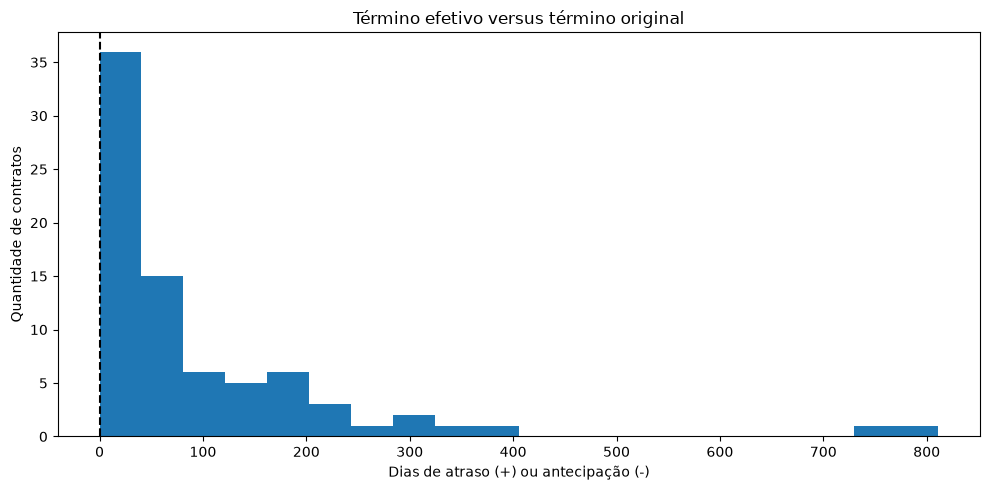

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(
    definitive_comparison["diferenca_conclusao_definitiva_original_dias"].dropna(),
    bins=20,
)
plt.axvline(0, color="black", linestyle="--")
plt.title("Conclusão definitiva versus término original")
plt.xlabel("Dias de atraso (+) ou antecipação (-)")
plt.ylabel("Quantidade de contratos")
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(
    definitive_comparison["diferenca_conclusao_definitiva_vigente_dias"].dropna(),
    bins=20,
)
plt.axvline(0, color="black", linestyle="--")
plt.title("Conclusão definitiva versus término vigente final")
plt.xlabel("Dias de atraso (+) ou antecipação (-)")
plt.ylabel("Quantidade de contratos")
plt.tight_layout()
plt.show()


## 7. Exportação

In [8]:
output_path = (
    REPORTS_DIR
    / "analise_rapida_prazos_com_conclusao_definitiva.csv"
)

analysis.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
)

print("Arquivo gerado:", output_path.resolve())
print("Existe:", output_path.exists())
print("Linhas:", len(analysis))


Arquivo gerado: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\reports\quick_analysis\analise_rapida_prazos_originais_e_efetivos.csv


## 8. Validação de consistência

A diferença assinada com o prazo vigente final deve ser compatível com `target_dias_atraso` do dataset de snapshots quando esse campo estiver disponível.


In [ ]:
if "target_dias_atraso" in latest.columns:
    check = pd.DataFrame({
        "id_contrato": latest["id_contrato"],
        "target_dias_atraso_dataset": pd.to_numeric(
            latest["target_dias_atraso"],
            errors="coerce",
        ),
    }).merge(
        analysis[
            ["id_contrato", "atraso_definitivo_dias"]
        ],
        on="id_contrato",
        how="left",
    )

    valid = check[
        check["target_dias_atraso_dataset"].notna()
        & check["atraso_definitivo_dias"].notna()
    ].copy()

    valid["diferenca_validacao"] = (
        valid["target_dias_atraso_dataset"]
        - valid["atraso_definitivo_dias"]
    )

    display(valid.head())

    assert valid["diferenca_validacao"].abs().max() < 1e-9, (
        "Há divergência entre o target do dataset e o atraso definitivo "
        "recalculado neste notebook."
    )

    print(
        "Validação concluída:",
        len(valid),
        "contratos com target compatível."
    )
else:
    print(
        "target_dias_atraso não encontrado no dataset; "
        "validação cruzada não executada."
    )
